<a href="https://colab.research.google.com/github/rahmanziaur/ML-Tute/blob/main/MangoLeafDiseaseAkash.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🥭 Mango Leaf Classification using MobileNetV2

A deep learning pipeline for **mango leaf disease/stress classification** using the **MangoLeafBD Dataset** and **MobileNetV2 transfer learning**.

The workflow includes:

* 📂 Dataset preparation
* 🔀 Train/validation/test splitting
* ⚡ Efficient TensorFlow data pipelines
* 🖼️ Training image visualization
* 🧠 MobileNetV2 transfer learning
* 🔄 Data augmentation
* 🏋️ Initial model training
* 🎯 Fine-tuning
* 💾 Best-model checkpointing

---

## 📋 Dataset

This project uses the **MangoLeafBD Dataset**, containing approximately **4,000 mango leaf images** distributed across multiple classes.

The expected dataset structure is:

```text
MangoLeafBD Dataset/
├── Class_1/
│   ├── image001.jpg
│   ├── image002.jpg
│   └── ...
├── Class_2/
│   ├── image001.jpg
│   └── ...
├── Class_3/
│   └── ...
└── ...
```

Each subdirectory represents one classification class.

---

# 🚀 1. Set the Dataset Path

```python
from pathlib import Path
import pandas as pd

DATASET_PATH = Path("/content/dataset/MangoLeafBD Dataset")

print("Dataset exists:", DATASET_PATH.exists())

classes = sorted([
    p.name for p in DATASET_PATH.iterdir()
    if p.is_dir()
])

print("Classes:")

for i, class_name in enumerate(classes):
    print(f"{i}: {class_name}")

print("\nNumber of classes:", len(classes))
```

### Expected Output

```text
Dataset exists: True

Classes:
0: Class_1
1: Class_2
2: Class_3
...

Number of classes: N
```

> **Note:** Make sure the dataset path matches the location where the dataset has been uploaded or mounted in Google Colab.

---

# 🔀 2. Create Training, Validation, and Test Datasets

The dataset is divided into:

| Dataset       | Percentage |
| ------------- | ---------: |
| 🏋️ Training  |    **70%** |
| 🔎 Validation |    **15%** |
| 🧪 Testing    |    **15%** |
| **Total**     |   **100%** |

We first reserve **30%** of the dataset and then split that portion equally between validation and testing.

```python
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42
```

### Create the Training Dataset

```python
train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)
```

### Create the Temporary Dataset

```python
temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Classes:", class_names)
```

The temporary dataset contains the remaining **30%** of the images.

We now divide it equally:

```python
temp_batches = tf.data.experimental.cardinality(temp_ds)

test_size = int(temp_batches * 0.5)

test_ds = temp_ds.take(test_size)
val_ds = temp_ds.skip(test_size)

print(
    "Train batches:",
    tf.data.experimental.cardinality(train_ds).numpy()
)

print(
    "Validation batches:",
    tf.data.experimental.cardinality(val_ds).numpy()
)

print(
    "Test batches:",
    tf.data.experimental.cardinality(test_ds).numpy()
)
```

> ⚠️ **Important:** Because the split is performed at the batch level, the exact number of images in validation and testing can differ slightly from exactly 15%.

---

# ⚡ 3. Improve Data Pipeline Performance

TensorFlow's `AUTOTUNE` is used to optimize data loading and preprocessing.

```python
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)
```

This allows data loading and model computation to overlap, improving training efficiency.

---

# 🖼️ 4. Visualize Training Images

Before training the model, it is useful to inspect sample images and verify their corresponding labels.

```python
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

for images, labels in train_ds.take(1):

    for i in range(12):

        plt.subplot(3, 4, i + 1)

        plt.imshow(
            images[i].numpy().astype("uint8")
        )

        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()
```

This visualization helps verify:

* Image loading
* Image dimensions
* Class labels
* Dataset quality
* Possible image anomalies

---

# 🧠 5. Build the Model Using MobileNetV2

For a dataset of approximately **4,000 images**, transfer learning provides an effective way to leverage features learned from a large image dataset.

We use **MobileNetV2** pretrained on **ImageNet**.

### Import Required Components

```python
from tensorflow.keras.applications import MobileNetV2

from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.models import Model
```

### Load the Pretrained Base Model

```python
NUM_CLASSES = len(class_names)

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False
```

Initially, the pretrained MobileNetV2 layers are frozen so that only the newly added classification layers are trained.

---

## 🔄 Data Augmentation

Data augmentation helps improve model generalization by exposing the model to different variations of training images.

```python
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])
```

The augmentation operations include:

| Augmentation    | Purpose                               |
| --------------- | ------------------------------------- |
| Random Flip     | Simulates different leaf orientations |
| Random Rotation | Handles changes in leaf angle         |
| Random Zoom     | Improves scale robustness             |
| Random Contrast | Handles lighting variation            |

---

## 🏗️ Create the Complete Model

```python
inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(
    x,
    training=False
)

x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dropout(0.3)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(
    inputs,
    outputs
)

model.summary()
```

### Model Architecture

```text
Input Image
   │
   ▼
224 × 224 × 3
   │
   ▼
Data Augmentation
   │
   ▼
MobileNetV2 Preprocessing
   │
   ▼
MobileNetV2 Backbone
   │
   ▼
Global Average Pooling
   │
   ▼
Batch Normalization
   │
   ▼
Dropout (0.3)
   │
   ▼
Dense Layer
   │
   ▼
Softmax Classification
   │
   ▼
Mango Leaf Class
```

---

# ⚙️ 6. Compile the Model

```python
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
```

### Configuration

| Parameter             | Value                           |
| --------------------- | ------------------------------- |
| Optimizer             | Adam                            |
| Initial Learning Rate | `0.001`                         |
| Loss                  | Sparse Categorical Crossentropy |
| Metric                | Accuracy                        |

---

# 🛡️ 7. Add Training Callbacks

Callbacks help prevent overfitting and automatically preserve the best-performing model.

```python
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [

    ModelCheckpoint(
        "/content/best_mango_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]
```

### Callback Functions

| Callback            | Purpose                                                    |
| ------------------- | ---------------------------------------------------------- |
| `ModelCheckpoint`   | Saves the best model                                       |
| `EarlyStopping`     | Stops training when validation performance stops improving |
| `ReduceLROnPlateau` | Reduces the learning rate when validation loss stagnates   |

The best model is saved as:

```text
/content/best_mango_model.keras
```

---

# 🏋️ 8. Train the Model

The first training stage trains only the newly added classification layers while the MobileNetV2 backbone remains frozen.

```python
EPOCHS = 20

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)
```

### Training Strategy

```text
MangoLeafBD Dataset
        │
        ▼
   70% Training
        │
        ▼
Data Augmentation
        │
        ▼
MobileNetV2 Frozen
        │
        ▼
Classification Head Training
        │
        ▼
Validation
        │
        ▼
Best Model Checkpoint
```

The best model will automatically be saved at:

```text
/content/best_mango_model.keras
```

---

# 🎯 9. Fine-Tune the Model

After the initial training phase, part of the pretrained MobileNetV2 network can be unfrozen.

This allows the model to adapt some of its pretrained visual features specifically to mango leaf images.

```python
base_model.trainable = True

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False
```

Only the final **30 layers** of MobileNetV2 are allowed to update.

---

## 🔧 Compile with a Lower Learning Rate

Fine-tuning requires a much smaller learning rate to avoid destroying useful pretrained features.

```python
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
```

---

## 🏃 Train the Fine-Tuned Model

```python
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=callbacks
)
```

### Fine-Tuning Strategy

```text
Pretrained MobileNetV2
        │
        ▼
Freeze Most Layers
        │
        ▼
Unfreeze Last 30 Layers
        │
        ▼
Lower Learning Rate
        │
        ▼
Fine-Tuning
        │
        ▼
Validation
        │
        ▼
Best Model
```

---

# 💾 10. Load the Best Model

After training, load the checkpoint that achieved the highest validation accuracy.

```python
best_model = tf.keras.models.load_model(
    "/content/best_mango_model.keras"
)

print("Best model loaded successfully.")
```

Verify the model:

```python
best_model.summary()
```

---

# 🧪 11. Evaluate the Model on the Test Dataset

The test dataset should be used only for the final unbiased evaluation.

```python
test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
```

The reported test accuracy represents the model's performance on previously unseen images.

---

# 📊 12. Plot Training History

Plot training and validation accuracy:

```python
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()
```

Plot training and validation loss:

```python
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()
```

---

# 🔍 13. Generate Predictions

Predictions can be generated for the test dataset using:

```python
import numpy as np

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(
        images,
        verbose=0
    )

    predicted_labels = np.argmax(
        predictions,
        axis=1
    )

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
```

---

# 📋 14. Classification Report

A detailed classification report can be generated using `scikit-learn`.

```python
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)
```

The report provides:

* Precision
* Recall
* F1-score
* Support

for every class.

---

# 🧩 15. Confusion Matrix

```python
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.colorbar()

plt.xticks(
    range(len(class_names)),
    class_names,
    rotation=90
)

plt.yticks(
    range(len(class_names)),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()
```

The confusion matrix helps identify which mango leaf classes are being confused by the model.

---

# 🔮 16. Predict a Single Image

A single mango leaf image can be classified using:

```python
from tensorflow.keras.utils import load_img
from tensorflow.keras.utils import img_to_array
import numpy as np

IMAGE_PATH = "/content/sample_mango_leaf.jpg"

image = load_img(
    IMAGE_PATH,
    target_size=IMG_SIZE
)

image_array = img_to_array(image)

image_array = np.expand_dims(
    image_array,
    axis=0
)

prediction = best_model.predict(
    image_array
)

predicted_class = class_names[
    np.argmax(prediction[0])
]

confidence = np.max(
    prediction[0]
)

print("Predicted Class:", predicted_class)
print(
    f"Confidence: {confidence * 100:.2f}%"
)
```

### Example Output

```text
Predicted Class: Class_3
Confidence: 94.72%
```

---

# 📦 17. Save the Final Model

The trained model can be exported for deployment.

```python
best_model.save(
    "/content/mango_leaf_classifier.keras"
)
```

The resulting file:

```text
mango_leaf_classifier.keras
```

can later be used for inference in a web application, mobile application, API, or agricultural decision-support system.

---

# 🗂️ Project Structure

A recommended project structure is:

```text
mango-leaf-classification/
│
├── README.md
│
├── dataset/
│   └── MangoLeafBD Dataset/
│       ├── Class_1/
│       ├── Class_2/
│       └── ...
│
├── notebooks/
│   └── mango_leaf_classification.ipynb
│
├── models/
│   └── best_mango_model.keras
│
├── results/
│   ├── training_history.png
│   ├── confusion_matrix.png
│   └── classification_report.txt
│
└── inference/
    └── predict.py
```

---

# 🧠 Overall Workflow

```text
                 MangoLeafBD Dataset
                          │
                          ▼
                Dataset Verification
                          │
                          ▼
                 70 / 15 / 15 Split
                          │
             ┌────────────┼────────────┐
             ▼            ▼            ▼
          Training    Validation      Test
             │
             ▼
       Data Augmentation
             │
             ▼
        MobileNetV2
       ImageNet Weights
             │
             ▼
       Frozen Backbone
             │
             ▼
     Classification Head
             │
             ▼
       Initial Training
             │
             ▼
        Fine-Tuning
             │
             ▼
       Best Checkpoint
             │
             ▼
        Test Evaluation
             │
             ▼
       Final Classifier
```

---

# ⚙️ Key Hyperparameters

| Parameter                 |          Setting |
| ------------------------- | ---------------: |
| Image Size                |      `224 × 224` |
| Batch Size                |             `32` |
| Random Seed               |             `42` |
| Training Split            |            `70%` |
| Validation Split          |            `15%` |
| Test Split                |            `15%` |
| Backbone                  |      MobileNetV2 |
| Pretrained Weights        |         ImageNet |
| Initial Learning Rate     |          `0.001` |
| Fine-Tuning Learning Rate |        `0.00001` |
| Initial Epochs            |             `20` |
| Fine-Tuning Epochs        |             `10` |
| Dropout                   |            `0.3` |
| Fine-Tuned Layers         | Last `30` layers |

---

# 📌 Notes

### Dataset Balance

Before training, it is recommended to inspect the number of images in each class. Significant class imbalance can negatively affect model performance.

### Data Leakage

Images originating from the same physical leaf, plant, or capture session should ideally not appear across training, validation, and test sets.

### Test Set Isolation

The test set should remain untouched during model development and hyperparameter tuning. It should be used only for final evaluation.

### Fine-Tuning

Fine-tuning should use a significantly lower learning rate than the initial transfer-learning stage.

---

# 🚀 Future Improvements

Potential extensions include:

* 🔬 Class-specific disease severity estimation
* 🧠 Explainable AI using Grad-CAM
* 📱 Mobile deployment using TensorFlow Lite
* 🌐 REST API deployment
* 📷 Real-time camera-based detection
* 🌦️ Integration with weather and environmental data
* 🌱 Crop-stage-aware disease prediction
* 🤖 LLM-based farmer advisory
* 📈 Continuous learning using newly collected field images

---

# 📄 License

Add the appropriate dataset and project license here.

---

# 👨‍💻 Project

**Mango Leaf Classification using Deep Transfer Learning**

Built with:

* Python
* TensorFlow / Keras
* MobileNetV2
* NumPy
* Pandas
* Matplotlib
* Scikit-learn


In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("nirmalsankalana/sugarcane-leaf-disease-dataset")

print("Path to dataset files:", path)

100%|██████████| 160M/160M [00:01<00:00, 162MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/nirmalsankalana/sugarcane-leaf-disease-dataset/versions/1


In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
from pathlib import Path

dataset_path = Path("/content/dataset/MangoLeafBD Dataset")

# Check if the folder exists
print("Exists:", dataset_path.exists())

# Show files and folders
for item in dataset_path.iterdir():
    print(item.name)

Exists: True
Die Back
Healthy
Anthracnose
Bacterial Canker
Sooty Mould
Powdery Mildew
Gall Midge
Cutting Weevil


In [7]:
import pandas as pd
from pathlib import Path

dataset_path = Path("/content/dataset/MangoLeafBD Dataset")

data = []

for file_path in dataset_path.rglob("*"):
    if file_path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
        data.append({
            "filepath": str(file_path),
            "class": file_path.parent.name
        })

df = pd.DataFrame(data)

print(df.head())
print("\nTotal images:", len(df))

print("\nImages per class:")
print(df["class"].value_counts())

                                            filepath     class
0  /content/dataset/MangoLeafBD Dataset/Die Back/...  Die Back
1  /content/dataset/MangoLeafBD Dataset/Die Back/...  Die Back
2  /content/dataset/MangoLeafBD Dataset/Die Back/...  Die Back
3  /content/dataset/MangoLeafBD Dataset/Die Back/...  Die Back
4  /content/dataset/MangoLeafBD Dataset/Die Back/...  Die Back

Total images: 4000

Images per class:
class
Die Back            500
Healthy             500
Anthracnose         500
Bacterial Canker    500
Sooty Mould         500
Powdery Mildew      500
Gall Midge          500
Cutting Weevil      500
Name: count, dtype: int64


In [8]:
from pathlib import Path
import pandas as pd

DATASET_PATH = Path("/content/dataset/MangoLeafBD Dataset")

print("Dataset exists:", DATASET_PATH.exists())

classes = sorted([p.name for p in DATASET_PATH.iterdir() if p.is_dir()])

print("Classes:")
for i, class_name in enumerate(classes):
    print(f"{i}: {class_name}")

print("\nNumber of classes:", len(classes))

Dataset exists: True
Classes:
0: Anthracnose
1: Bacterial Canker
2: Cutting Weevil
3: Die Back
4: Gall Midge
5: Healthy
6: Powdery Mildew
7: Sooty Mould

Number of classes: 8


In [12]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Classes:", class_names)

Found 4000 files belonging to 8 classes.
Using 2800 files for training.
Found 4000 files belonging to 8 classes.
Using 1200 files for validation.
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


In [14]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

temp_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.30,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

# Get the number of batches as a Python integer
temp_batches = tf.data.experimental.cardinality(temp_ds).numpy()

# Split remaining data approximately 50/50
test_size = temp_batches // 2

test_ds = temp_ds.take(test_size)
val_ds = temp_ds.skip(test_size)

print("\nClasses:", class_names)

print("\nTrain batches:",
      tf.data.experimental.cardinality(train_ds).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(val_ds).numpy())

print("Test batches:",
      tf.data.experimental.cardinality(test_ds).numpy())

Found 4000 files belonging to 8 classes.
Using 2800 files for training.
Found 4000 files belonging to 8 classes.
Using 1200 files for validation.

Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']

Train batches: 88
Validation batches: 19
Test batches: 19


In [17]:
temp_batches = int(tf.data.experimental.cardinality(temp_ds))

test_size = int(temp_batches * 0.5)

test_ds = temp_ds.take(test_size)
val_ds = temp_ds.skip(test_size)

print("Train batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Test batches:", tf.data.experimental.cardinality(test_ds).numpy())




Train batches: 88
Validation batches: 19
Test batches: 19


In [18]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

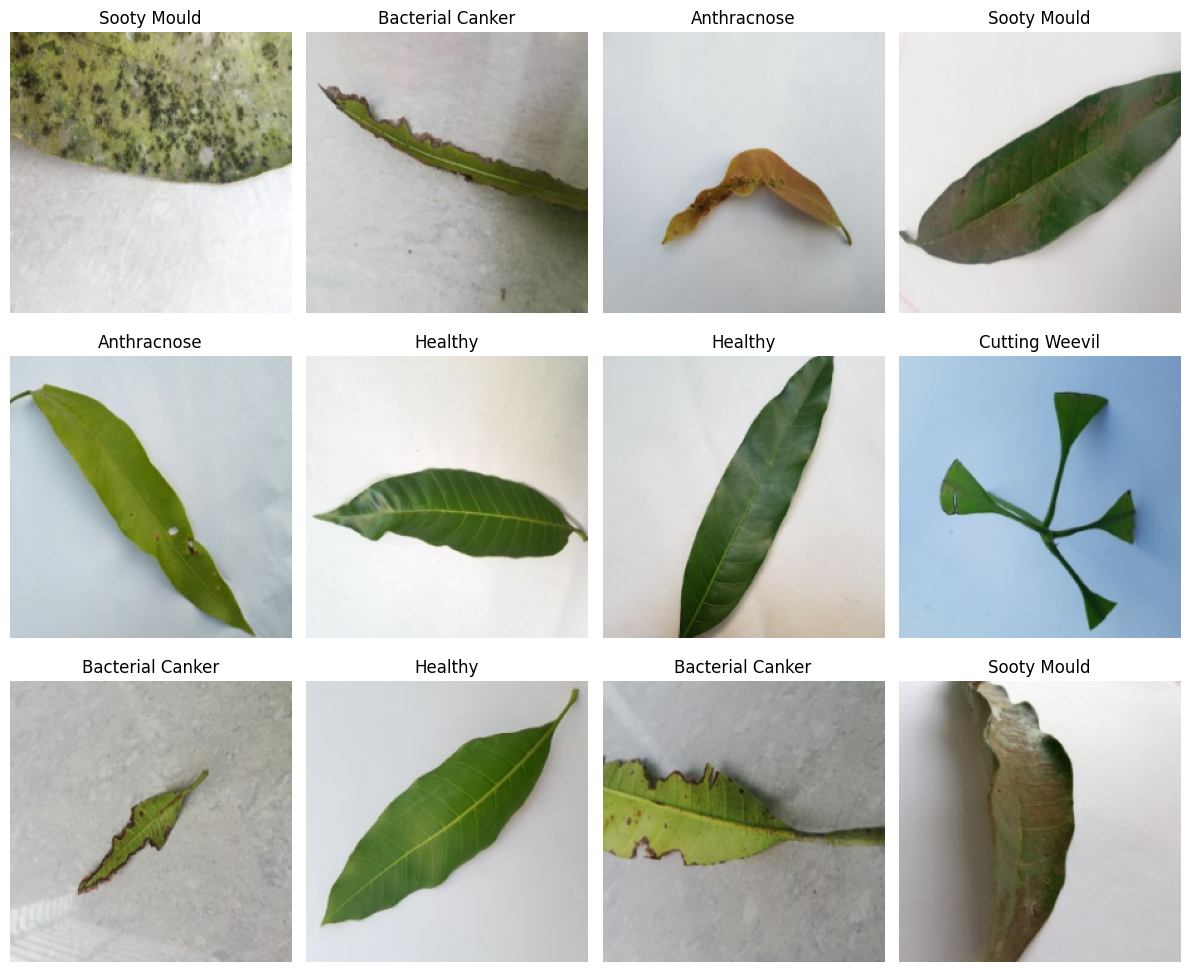

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))

for images, labels in train_ds.take(1):

    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.models import Model

NUM_CLASSES = len(class_names)

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [21]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

In [22]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

# MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = GlobalAveragePooling2D()(x)

x = BatchNormalization()(x)

x = Dropout(0.3)(x)

outputs = Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,352 (8.67 MB)

 Trainable params: 12,808 (50.03 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [23]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [24]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [

    ModelCheckpoint(
        "/content/best_mango_model.keras",
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

In [26]:
EPOCHS = 3

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/3
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6645 - loss: 1.0240
Epoch 1: val_accuracy improved from None to 0.94932, saving model to /content/best_mango_model.keras

Epoch 1: finished saving model to /content/best_mango_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 213s 2s/step - accuracy: 0.8214 - loss: 0.5362 - val_accuracy: 0.9493 - val_loss: 0.2086 - learning_rate: 0.0010
Epoch 2/3
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9585 - loss: 0.1358
Epoch 2: val_accuracy improved from 0.94932 to 0.97804, saving model to /content/best_mango_model.keras

Epoch 2: finished saving model to /content/best_mango_model.keras
88/88 ━━━━━━━━━━━━━━━━━━━━ 201s 2s/step - accuracy: 0.9557 - loss: 0.1403 - val_accuracy: 0.9780 - val_loss: 0.0812 - learning_rate: 0.0010
Epoch 3/3
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9639 - loss: 0.0952
Epoch 3: val_accuracy improved from 0.97804 to 0.98649, saving model to /content/best_mango_model.keras

Epoch 3: finished saving model

In [27]:
base_model.trainable = True

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

In [28]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [30]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=2,
    callbacks=callbacks
)

Epoch 1/2
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9311 - loss: 0.2010
Epoch 1: val_accuracy did not improve from 0.98649
88/88 ━━━━━━━━━━━━━━━━━━━━ 270s 3s/step - accuracy: 0.9382 - loss: 0.1840 - val_accuracy: 0.9645 - val_loss: 0.0860 - learning_rate: 1.0000e-05
Epoch 2/2
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9522 - loss: 0.1444
Epoch 2: val_accuracy did not improve from 0.98649

Epoch 2: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
88/88 ━━━━━━━━━━━━━━━━━━━━ 248s 3s/step - accuracy: 0.9564 - loss: 0.1351 - val_accuracy: 0.9662 - val_loss: 0.1033 - learning_rate: 1.0000e-05


In [31]:
best_model = tf.keras.models.load_model(
    "/content/best_mango_model.keras"
)

In [32]:
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

19/19 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.9885 - loss: 0.0502
Test Loss: 0.0502
Test Accuracy: 98.85%


In [33]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = best_model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

                  precision    recall  f1-score   support

     Anthracnose       1.00      0.99      0.99        80
Bacterial Canker       1.00      1.00      1.00        73
  Cutting Weevil       0.99      1.00      0.99        72
        Die Back       1.00      1.00      1.00        74
      Gall Midge       0.99      0.96      0.97        78
         Healthy       1.00      1.00      1.00        81
  Powdery Mildew       1.00      0.98      0.99        84
     Sooty Mould       0.94      1.00      0.97        66

        accuracy                           0.99       608
       macro avg       0.99      0.99      0.99       608
    weighted avg       0.99      0.99      0.99       608



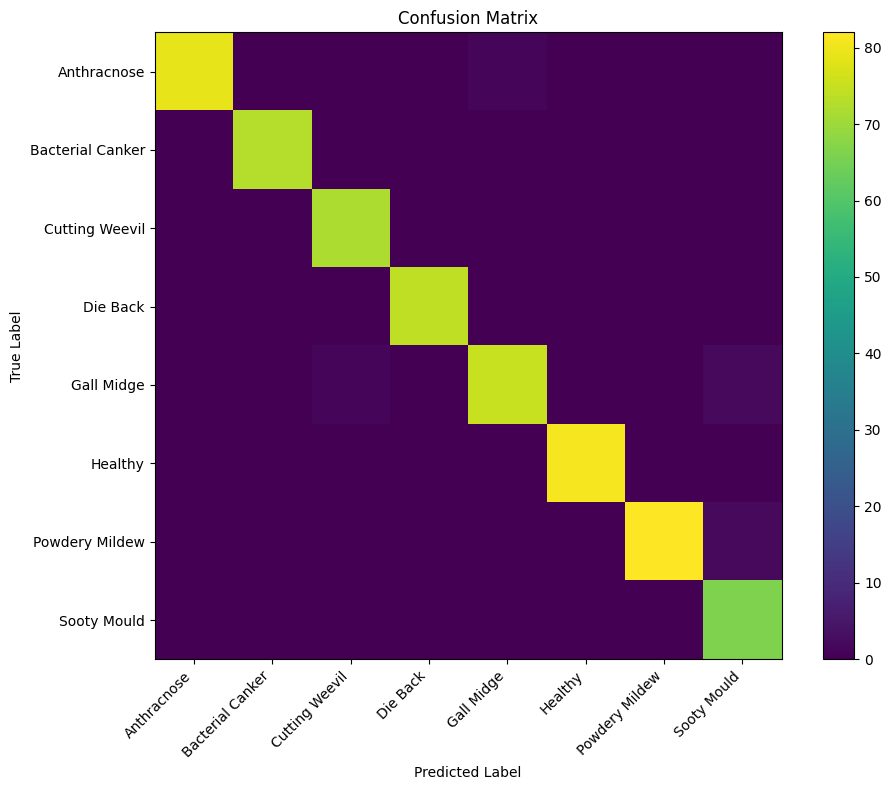

In [34]:
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.colorbar()
plt.tight_layout()

plt.show()

In [35]:
import json

with open("/content/class_names.json", "w") as f:
    json.dump(class_names, f)

print(class_names)

['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


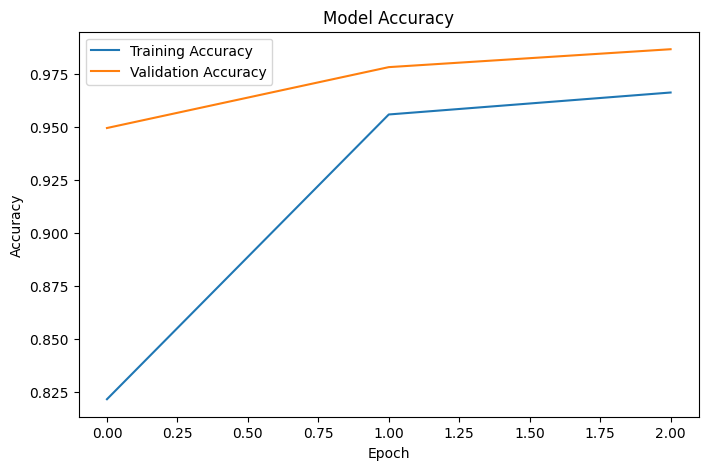

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

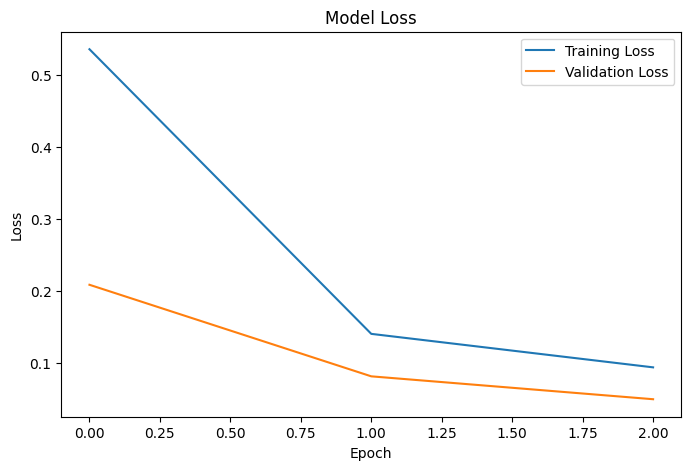

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [38]:
!pip install -q gradio

In [39]:
import gradio as gr
import numpy as np
import tensorflow as tf
import json

# Load model
model = tf.keras.models.load_model(
    "/content/best_mango_model.keras"
)

# Load class names
with open("/content/class_names.json", "r") as f:
    class_names = json.load(f)


def predict_mango_disease(image):

    # Resize image
    image = image.resize((224, 224))

    # Convert to NumPy array
    image_array = np.array(image)

    # Remove alpha channel if present
    if image_array.shape[-1] == 4:
        image_array = image_array[:, :, :3]

    # Add batch dimension
    image_array = np.expand_dims(image_array, axis=0)

    # Prediction
    predictions = model.predict(
        image_array,
        verbose=0
    )[0]

    # Return class probabilities
    results = {
        class_names[i]: float(predictions[i])
        for i in range(len(class_names))
    }

    return results

In [40]:
demo = gr.Interface(
    fn=predict_mango_disease,

    inputs=gr.Image(
        type="pil",
        label="Upload Mango Leaf Image"
    ),

    outputs=gr.Label(
        num_top_classes=3,
        label="Prediction"
    ),

    title="🥭 Mango Leaf Disease Detection",

    description="""
Upload an image of a mango leaf.

The AI model will classify it into one of the following categories:

• Anthracnose
• Bacterial Canker
• Cutting Weevil
• Die Back
• Gall Midge
• Healthy
• Powdery Mildew
• Sooty Mould
"""
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4be0c89b445a4ad8d7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [41]:
from google.colab import files

files.download("/content/best_mango_model.keras")
files.download("/content/class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>